# Venetoclax TransCell score and ex vivo AUC

Major comment 1, same split as Figure 3C. De novo patients are divided by bone-marrow blast percentage: below 50% and above 50%. Within each group, the venetoclax TransCell score is compared with ex vivo AUC for bulk RNA-seq and for each reference. A lower score means higher predicted sensitivity, and a lower AUC means greater sensitivity. A positive Spearman correlation means the two agree.

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
from pandas import DataFrame
from scipy.stats import spearmanr

In [ ]:
# Paths are relative to the project folder: inputs in data/, files written by
# earlier notebooks in results/, figures in figures/.
DATA_DIR = 'data'
RESULTS_DIR = 'results'
FIGURE_DIR = 'figures'

# Input files
TRANSCELL_RESULTS = f'{DATA_DIR}/ALLDECONVALID_results.csv'
DRUG_AUC = f'{DATA_DIR}/beataml2_patients_drug.csv'
CLINICAL = f'{DATA_DIR}/beataml2_data.csv'

In [35]:
total_df = pd.read_csv(TRANSCELL_RESULTS, index_col=0)
drugs = pd.read_csv(DRUG_AUC)
clin = pd.read_csv(CLINICAL, low_memory=False)

In [36]:
# de novo sample at inclusion, same patients the scores were made for
denovo = clin[(clin['isDenovo'].astype(str).str.upper() == 'TRUE')
              & (clin['timeOfSampleCollectionRelativeToInclusion'] == 0)].copy()
denovo['pid'] = denovo['dbgap_subject_id'].astype(int)
denovo = denovo.drop_duplicates('pid')
denovo['blast'] = pd.to_numeric(denovo['%.Blasts.in.BM'], errors='coerce')
denovo['group'] = pd.Series(index=denovo.index, dtype='object')
denovo.loc[denovo['blast'] < 50, 'group'] = 'low progenitor (<50% blasts)'
denovo.loc[denovo['blast'] > 50, 'group'] = 'high progenitor (>50% blasts)'

ven = drugs[drugs['inhibitor'] == 'Venetoclax'].copy()
ven['pid'] = ven['dbgap_subject_id'].astype(int)
ven = ven[ven['pid'].isin(denovo['pid'])]
auc = ven.groupby('pid')['auc'].mean()
print(len(denovo), 'de novo patients,', len(ven), 'venetoclax curves,', len(auc), 'with an AUC')

379 de novo patients, 195 venetoclax curves, 181 with an AUC


In [37]:
list_refs = ['P38', 'P14', 'P30', 'P23', 'P34', 'P25', 'P20', 'P36']

one = total_df.loc['venetoclax']
wide = DataFrame({'ref': one.index.str.split('_').str[0],
                  'pid': one.index.str.split('_').str[1].astype(int),
                  'v': one.values}).pivot_table(index='pid', columns='ref', values='v')
wide = wide.reindex(columns=['Bulk'] + list_refs).reindex(auc.index)
print(wide.notna().sum().to_dict())

{'Bulk': 52, 'P38': 52, 'P14': 52, 'P30': 52, 'P23': 52, 'P34': 52, 'P25': 52, 'P20': 52, 'P36': 52}


In [38]:
# positive rho: lower TransCell score with lower AUC
blast = denovo.drop_duplicates('pid').set_index('pid')['group']
rows = []
for group in ['low progenitor (<50% blasts)', 'high progenitor (>50% blasts)']:
    ids = blast[blast == group].index
    for m in wide.columns:
        d = DataFrame({'score': wide[m], 'auc': auc}).reindex(ids).dropna()
        if len(d) < 5:
            rows.append([group, m, len(d), None, None])
            continue
        rho, p = spearmanr(d.score, d.auc)
        rows.append([group, m, len(d), rho, p])
corr_df = DataFrame(rows, columns=['group', 'method', 'n', 'rho', 'p'])
corr_df.round(3)

/var/folders/3p/qzzcgxt56snd0tt5kns631pw0000gq/T/ipykernel_95665/1293582383.py:11: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  rho, p = spearmanr(d.score, d.auc)


,group,method,n,rho,p
0,low progenitor (<50% blasts),Bulk,13,-0.159,0.603
1,low progenitor (<50% blasts),P38,13,0.484,0.094
2,low progenitor (<50% blasts),P14,13,0.440,0.133
3,low progenitor (<50% blasts),P30,13,0.121,0.694
4,low progenitor (<50% blasts),P23,13,-0.135,0.661
5,low progenitor (<50% blasts),P34,13,-0.322,0.283
6,low progenitor (<50% blasts),P25,13,-0.008,0.978
7,low progenitor (<50% blasts),P20,13,NaN,NaN
8,low progenitor (<50% blasts),P36,13,-0.286,0.344
9,high progenitor (>50% blasts),Bulk,33,0.157,0.384


/var/folders/3p/qzzcgxt56snd0tt5kns631pw0000gq/T/ipykernel_95665/3499476416.py:13: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  rho, p = spearmanr(d.score, d.auc)


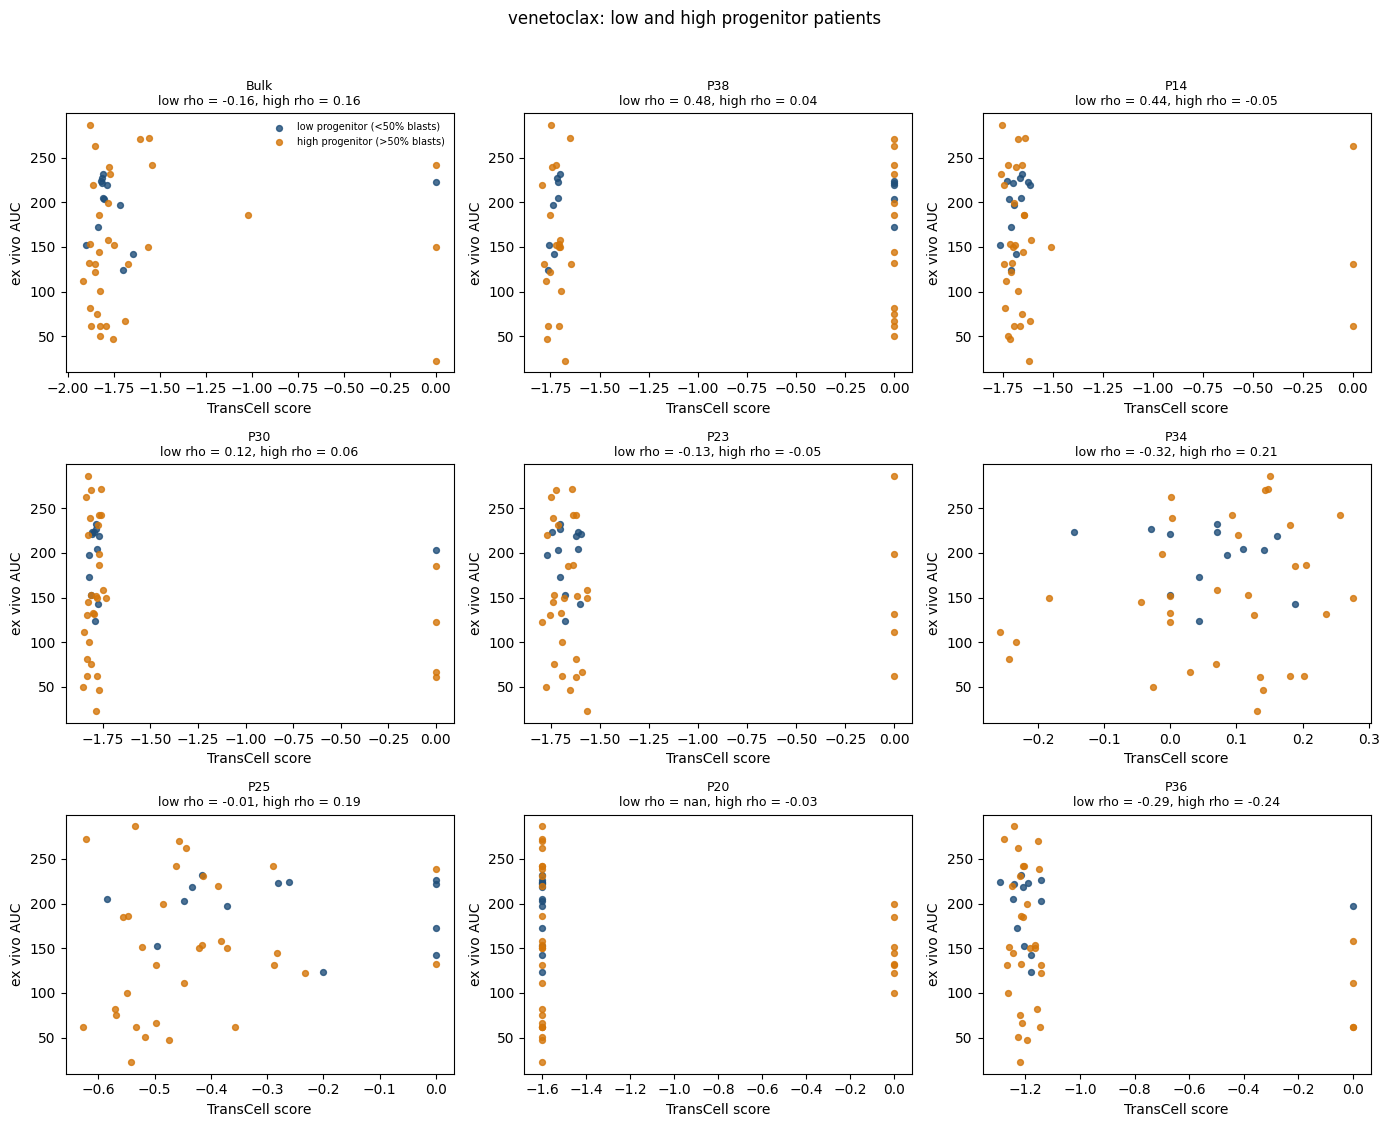

In [39]:
colors = {
    'low progenitor (<50% blasts)': '#1f4e79',
    'high progenitor (>50% blasts)': '#d4760a',
}
fig, axes = plt.subplots(3, 3, figsize=(14, 11))
for ax, m in zip(axes.flatten(), wide.columns):
    bits = []
    for group, color in colors.items():
        ids = blast[blast == group].index
        d = DataFrame({'score': wide[m], 'auc': auc}).reindex(ids).dropna()
        ax.scatter(d.score, d.auc, s=18, c=color, alpha=0.8, label=group)
        if len(d) >= 5:
            rho, p = spearmanr(d.score, d.auc)
            bits.append(f'{group.split()[0]} rho = {rho:.2f}')
    ax.set_title(m + '\n' + ', '.join(bits), fontsize=9)
    ax.set_xlabel('TransCell score')
    ax.set_ylabel('ex vivo AUC')
axes[0, 0].legend(fontsize=7, frameon=False)
fig.suptitle('venetoclax: low and high progenitor patients', y=1.02)
plt.tight_layout()
plt.show()

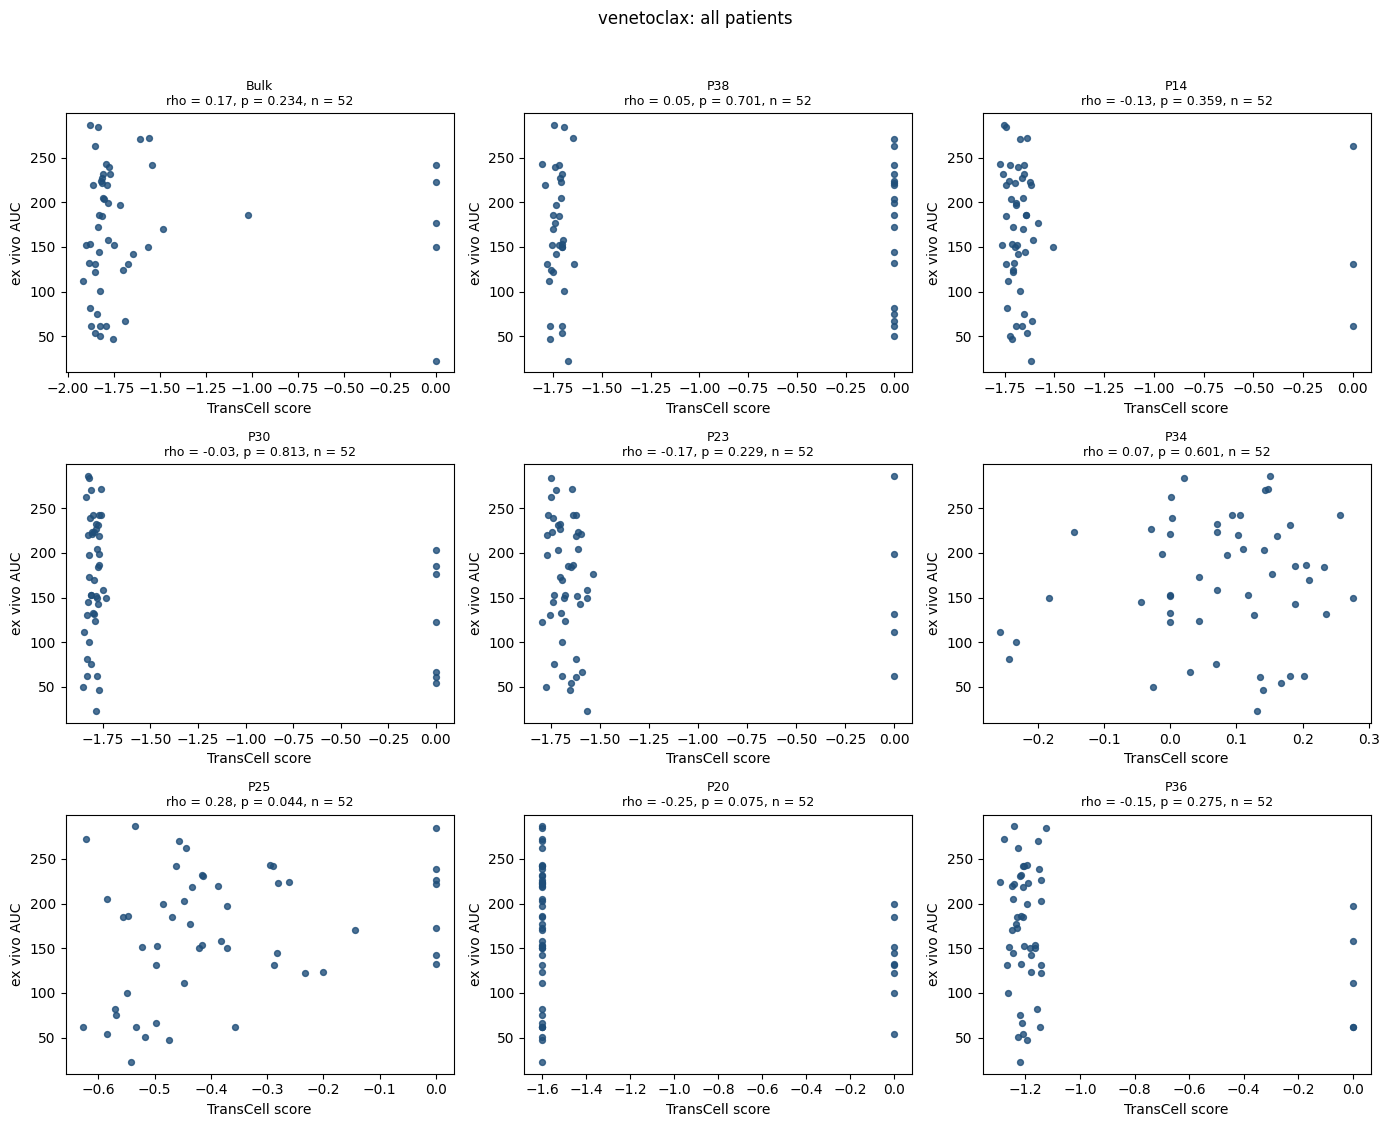

In [40]:
# All de novo patients. No blast split.
fig, axes = plt.subplots(3, 3, figsize=(14, 11))
for ax, m in zip(axes.flatten(), wide.columns):
    d = DataFrame({'score': wide[m], 'auc': auc}).dropna()
    ax.scatter(d.score, d.auc, s=18, c='#1f4e79', alpha=0.8)
    rho, p = spearmanr(d.score, d.auc)
    ax.set_title(f'{m}\nrho = {rho:.2f}, p = {p:.3f}, n = {len(d)}', fontsize=9)
    ax.set_xlabel('TransCell score')
    ax.set_ylabel('ex vivo AUC')
fig.suptitle('venetoclax: all patients', y=1.02)
plt.tight_layout()
plt.show()

/var/folders/3p/qzzcgxt56snd0tt5kns631pw0000gq/T/ipykernel_95665/3023514540.py:8: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  rho, p = spearmanr(d.score, d.auc)


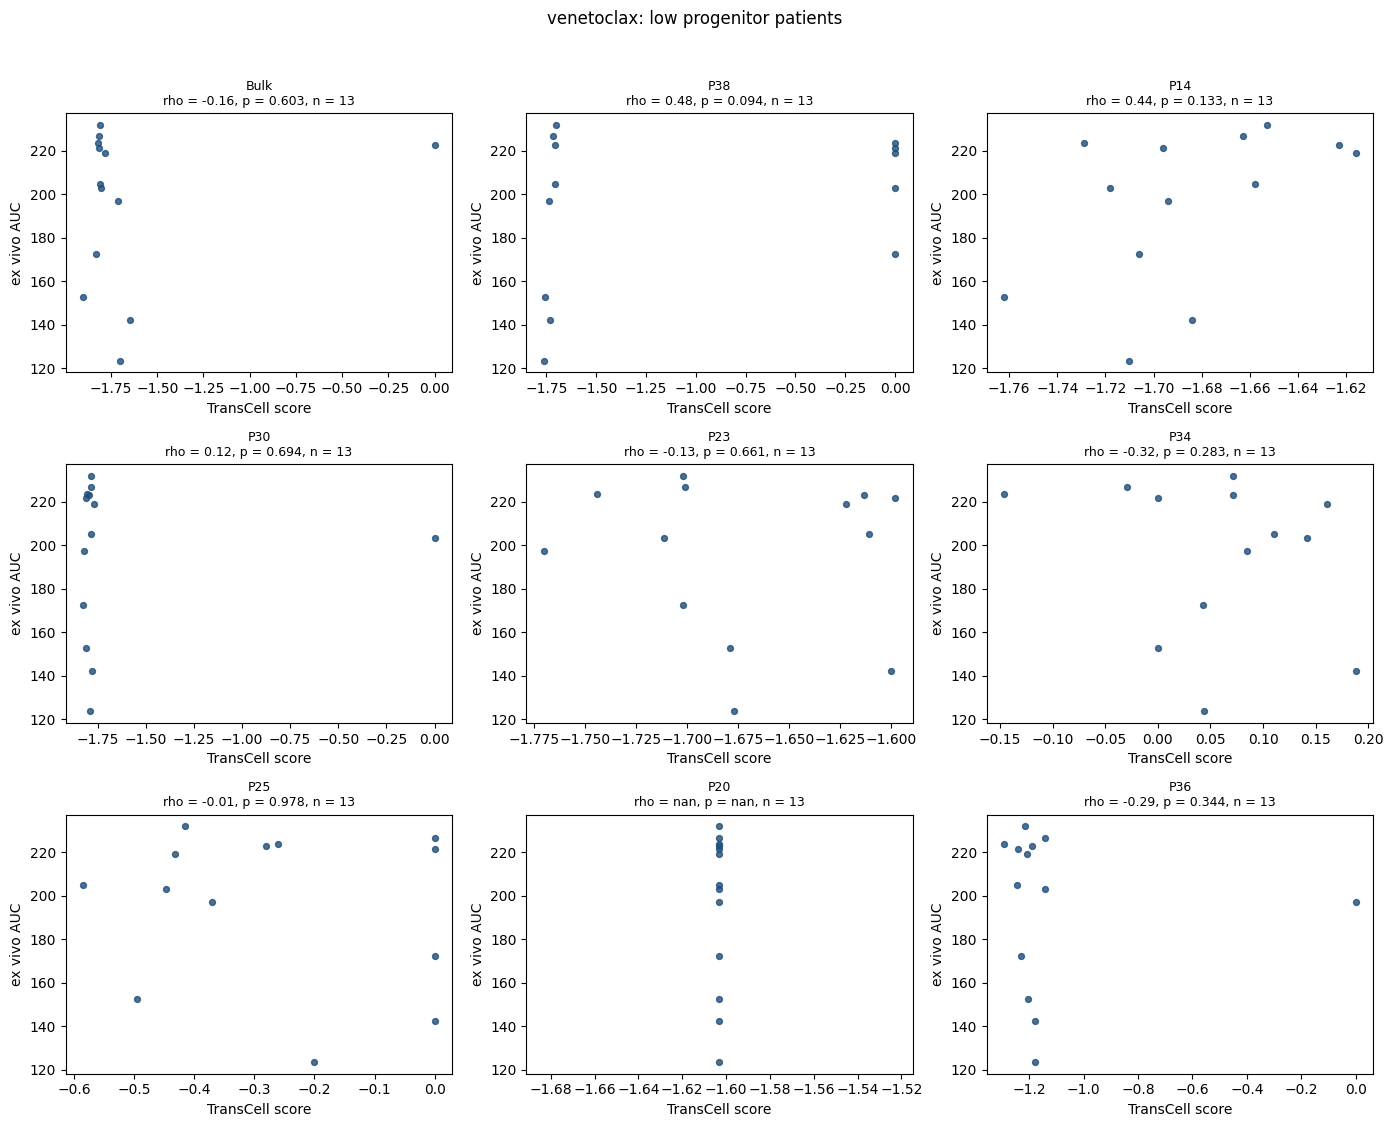

In [41]:
# Low progenitor patients only. Bone-marrow blasts below 50%.
ids = denovo.loc[denovo['group'] == 'low progenitor (<50% blasts)', 'pid']
fig, axes = plt.subplots(3, 3, figsize=(14, 11))
for ax, m in zip(axes.flatten(), wide.columns):
    d = DataFrame({'score': wide[m], 'auc': auc}).reindex(ids).dropna()
    ax.scatter(d.score, d.auc, s=18, c='#1f4e79', alpha=0.8)
    if len(d) >= 5:
        rho, p = spearmanr(d.score, d.auc)
        ax.set_title(f'{m}\nrho = {rho:.2f}, p = {p:.3f}, n = {len(d)}', fontsize=9)
    else:
        ax.set_title(f'{m}\nn = {len(d)}', fontsize=9)
    ax.set_xlabel('TransCell score')
    ax.set_ylabel('ex vivo AUC')
fig.suptitle('venetoclax: low progenitor patients', y=1.02)
plt.tight_layout()
plt.show()

In [42]:
# IC50 as well as AUC. A higher IC50 means less sensitive.
ic50 = ven.groupby('pid')['ic50'].mean()
print(int(ic50.notna().sum()), 'with an IC50')
print(int((ven.ic50 <= ven.min_conc).sum()), 'curves at the lowest tested dose,',
      int((ven.ic50 >= ven.max_conc).sum()), 'curves at the highest tested dose')

181 with an IC50
55 curves at the lowest tested dose, 64 curves at the highest tested dose


In [43]:
# positive rho: lower TransCell score with lower IC50
rows = []
for group in ['low progenitor (<50% blasts)', 'high progenitor (>50% blasts)']:
    ids = blast[blast == group].index
    for m in wide.columns:
        d = DataFrame({'score': wide[m], 'ic50': ic50}).reindex(ids).dropna()
        if len(d) < 5:
            rows.append([group, m, len(d), None, None])
            continue
        rho, p = spearmanr(d.score, d.ic50)
        rows.append([group, m, len(d), rho, p])
ic50_corr_df = DataFrame(rows, columns=['group', 'method', 'n', 'rho', 'p'])
ic50_corr_df.round(3)

/var/folders/3p/qzzcgxt56snd0tt5kns631pw0000gq/T/ipykernel_95665/1360027852.py:10: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  rho, p = spearmanr(d.score, d.ic50)


,group,method,n,rho,p
0,low progenitor (<50% blasts),Bulk,13,-0.152,0.619
1,low progenitor (<50% blasts),P38,13,0.674,0.012
2,low progenitor (<50% blasts),P14,13,0.357,0.232
3,low progenitor (<50% blasts),P30,13,-0.030,0.923
4,low progenitor (<50% blasts),P23,13,-0.320,0.287
5,low progenitor (<50% blasts),P34,13,-0.125,0.685
6,low progenitor (<50% blasts),P25,13,-0.092,0.764
7,low progenitor (<50% blasts),P20,13,NaN,NaN
8,low progenitor (<50% blasts),P36,13,-0.234,0.441
9,high progenitor (>50% blasts),Bulk,33,0.169,0.346


/var/folders/3p/qzzcgxt56snd0tt5kns631pw0000gq/T/ipykernel_95665/1808938326.py:13: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  rho, p = spearmanr(d.score, d.ic50)


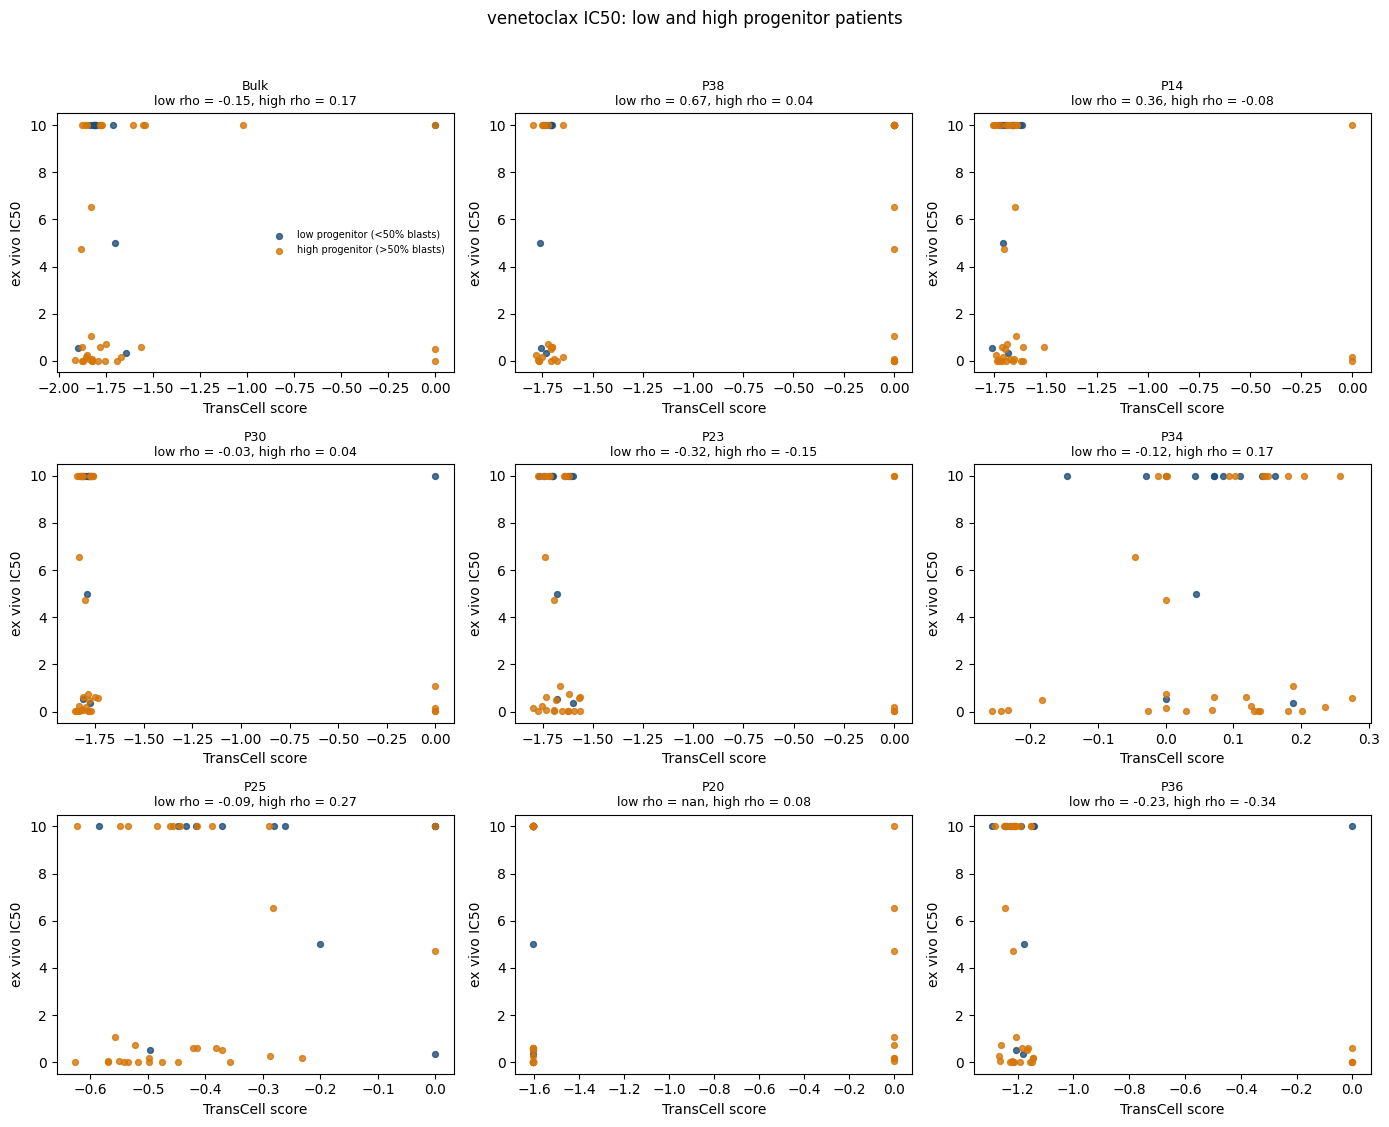

In [44]:
colors = {
    'low progenitor (<50% blasts)': '#1f4e79',
    'high progenitor (>50% blasts)': '#d4760a',
}
fig, axes = plt.subplots(3, 3, figsize=(14, 11))
for ax, m in zip(axes.flatten(), wide.columns):
    bits = []
    for group, color in colors.items():
        ids = blast[blast == group].index
        d = DataFrame({'score': wide[m], 'ic50': ic50}).reindex(ids).dropna()
        ax.scatter(d.score, d.ic50, s=18, c=color, alpha=0.8, label=group)
        if len(d) >= 5:
            rho, p = spearmanr(d.score, d.ic50)
            bits.append(f'{group.split()[0]} rho = {rho:.2f}')
    ax.set_title(m + '\n' + ', '.join(bits), fontsize=9)
    ax.set_xlabel('TransCell score')
    ax.set_ylabel('ex vivo IC50')
axes[0, 0].legend(fontsize=7, frameon=False)
fig.suptitle('venetoclax IC50: low and high progenitor patients', y=1.02)
plt.tight_layout()
plt.show()

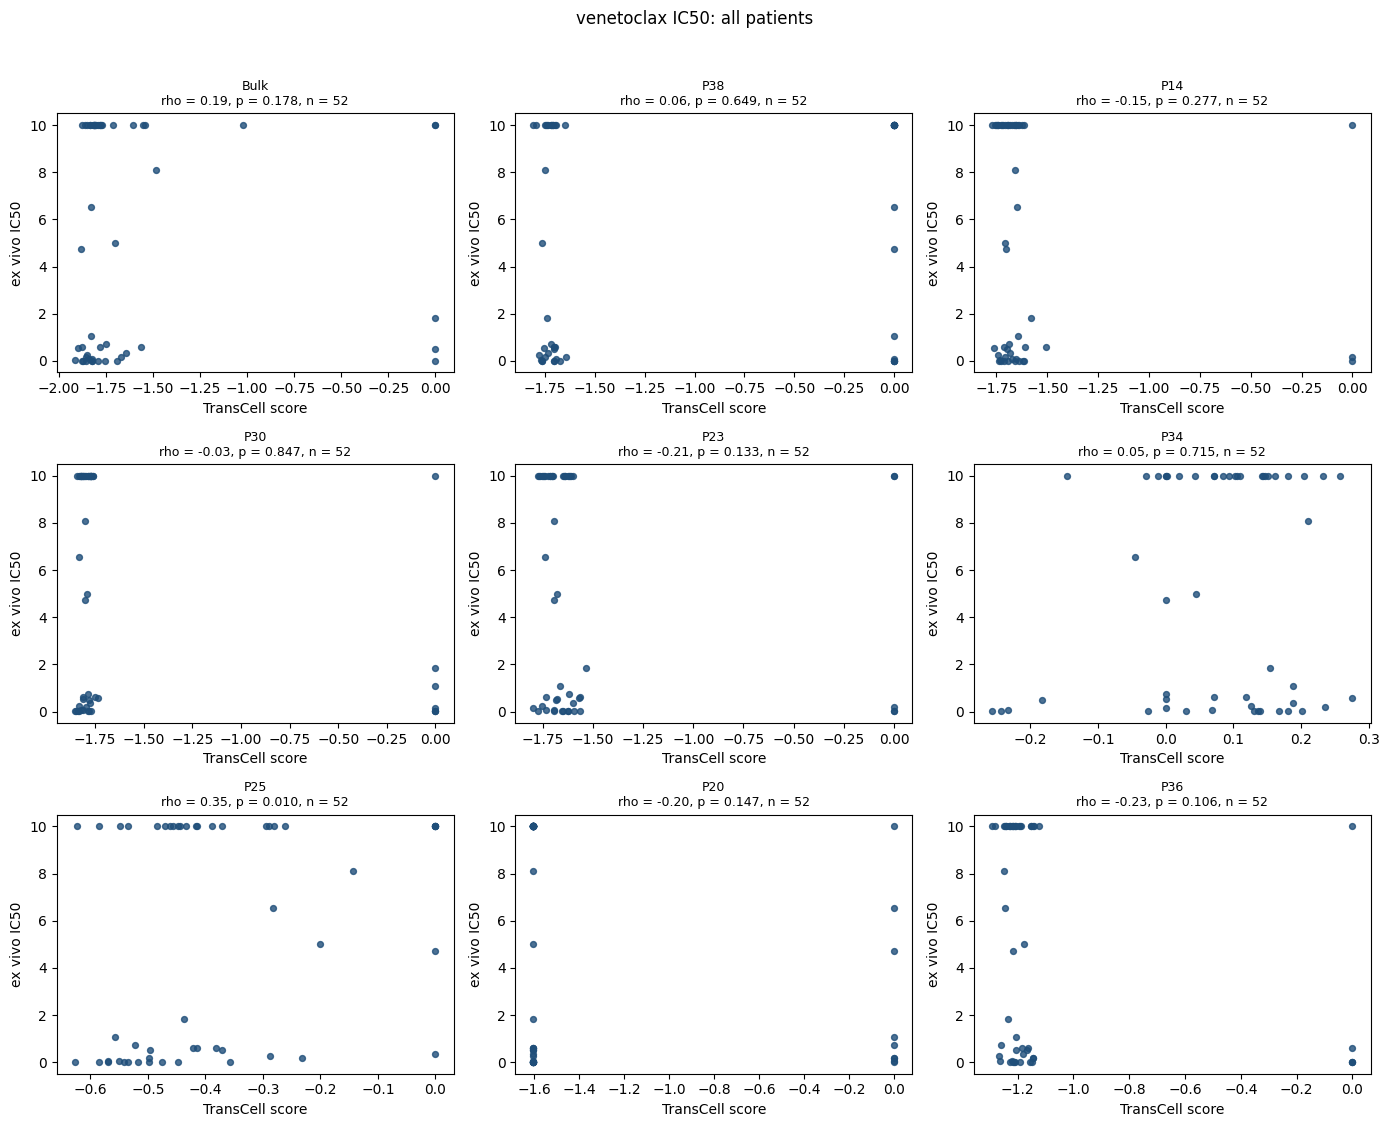

In [45]:
# All de novo patients. No blast split. IC50.
fig, axes = plt.subplots(3, 3, figsize=(14, 11))
for ax, m in zip(axes.flatten(), wide.columns):
    d = DataFrame({'score': wide[m], 'ic50': ic50}).dropna()
    ax.scatter(d.score, d.ic50, s=18, c='#1f4e79', alpha=0.8)
    rho, p = spearmanr(d.score, d.ic50)
    ax.set_title(f'{m}\nrho = {rho:.2f}, p = {p:.3f}, n = {len(d)}', fontsize=9)
    ax.set_xlabel('TransCell score')
    ax.set_ylabel('ex vivo IC50')
fig.suptitle('venetoclax IC50: all patients', y=1.02)
plt.tight_layout()
plt.show()

/var/folders/3p/qzzcgxt56snd0tt5kns631pw0000gq/T/ipykernel_95665/2702018061.py:8: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  rho, p = spearmanr(d.score, d.ic50)


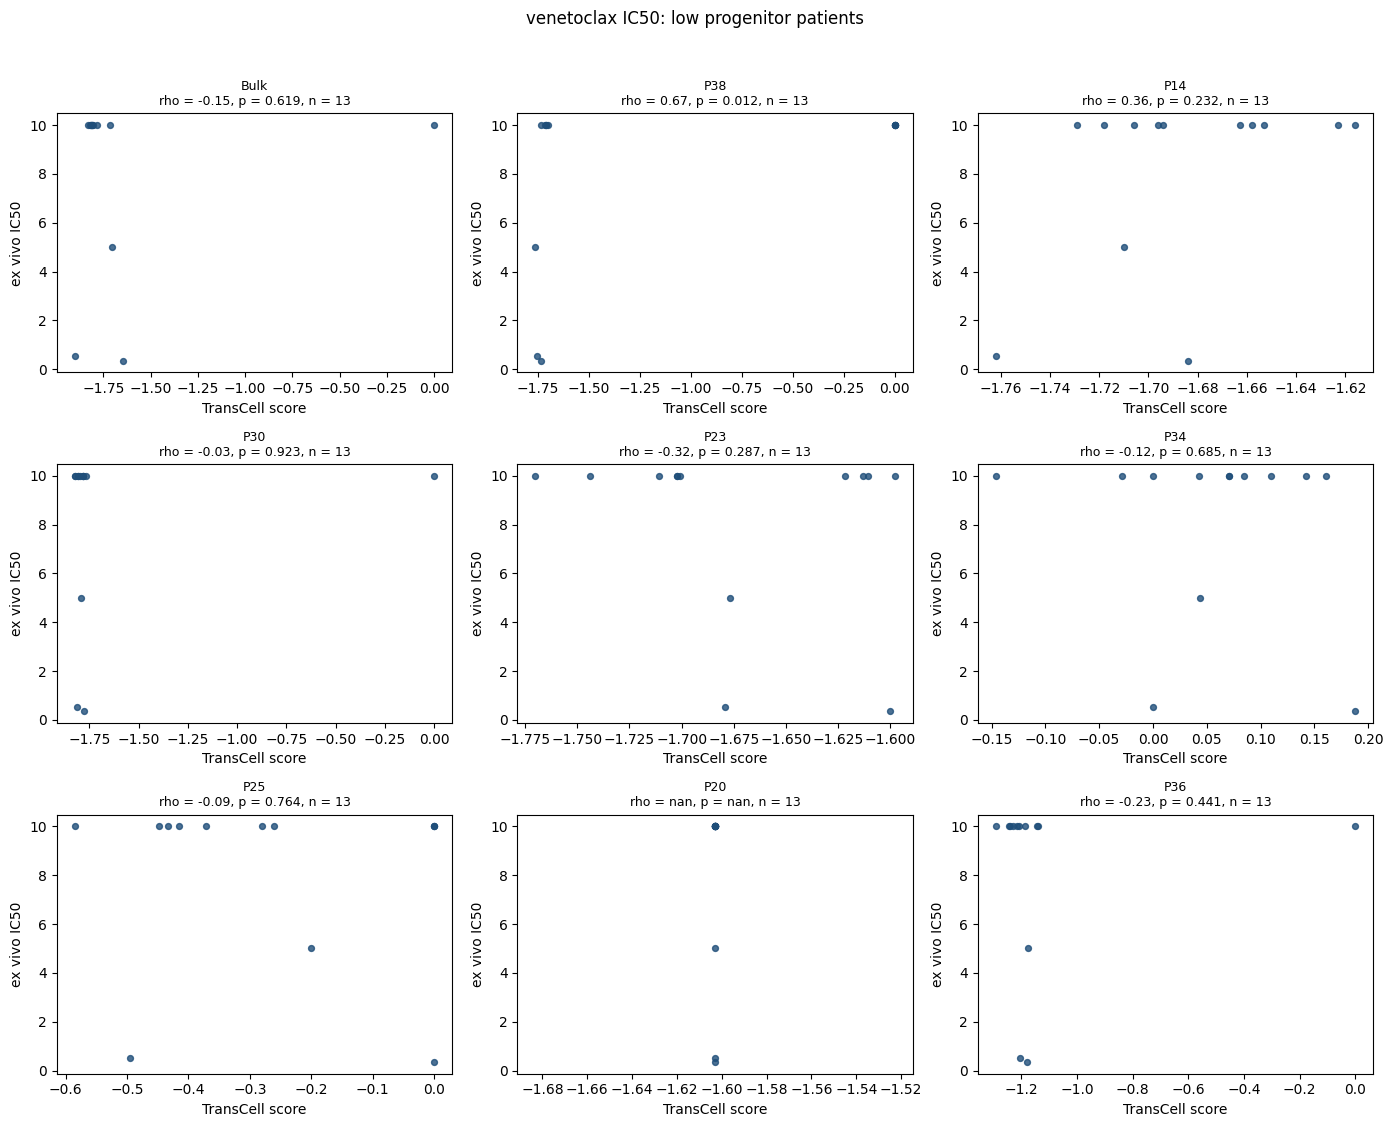

In [46]:
# Low progenitor patients only. Bone-marrow blasts below 50%. IC50.
ids = denovo.loc[denovo['group'] == 'low progenitor (<50% blasts)', 'pid']
fig, axes = plt.subplots(3, 3, figsize=(14, 11))
for ax, m in zip(axes.flatten(), wide.columns):
    d = DataFrame({'score': wide[m], 'ic50': ic50}).reindex(ids).dropna()
    ax.scatter(d.score, d.ic50, s=18, c='#1f4e79', alpha=0.8)
    if len(d) >= 5:
        rho, p = spearmanr(d.score, d.ic50)
        ax.set_title(f'{m}\nrho = {rho:.2f}, p = {p:.3f}, n = {len(d)}', fontsize=9)
    else:
        ax.set_title(f'{m}\nn = {len(d)}', fontsize=9)
    ax.set_xlabel('TransCell score')
    ax.set_ylabel('ex vivo IC50')
fig.suptitle('venetoclax IC50: low progenitor patients', y=1.02)
plt.tight_layout()
plt.show()